In [14]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr, L500_from_T500, Linj_from_L500, T500_from_L500
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
data, var = load_data_and_var()

In [4]:
all_nfws = generate_nfws_from_combined_dataset_werr(data, var)

In [5]:
nfws = [nfw for nfw in all_nfws if nfw.energies.is_virialized_gaspari]

In [6]:
test_nfw = nfws[0]

In [7]:
rmin = 0.001*test_nfw.R500
rmax = test_nfw.R500
rc=0.1*test_nfw.R500

In [84]:
L500s = np.logspace(-2, 30) # in units 1e44 erg/s
L500s

array([1.00000000e-02, 4.49843267e-02, 2.02358965e-01, 9.10298178e-01,
       4.09491506e+00, 1.84206997e+01, 8.28642773e+01, 3.72759372e+02,
       1.67683294e+03, 7.54312006e+03, 3.39322177e+04, 1.52641797e+05,
       6.86648845e+05, 3.08884360e+06, 1.38949549e+07, 6.25055193e+07,
       2.81176870e+08, 1.26485522e+09, 5.68986603e+09, 2.55954792e+10,
       1.15139540e+11, 5.17947468e+11, 2.32995181e+12, 1.04811313e+13,
       4.71486636e+13, 2.12095089e+14, 9.54095476e+14, 4.29193426e+15,
       1.93069773e+16, 8.68511374e+16, 3.90693994e+17, 1.75751062e+18,
       7.90604321e+18, 3.55648031e+19, 1.59985872e+20, 7.19685673e+20,
       3.23745754e+21, 1.45634848e+22, 6.55128557e+22, 2.94705170e+23,
       1.32571137e+24, 5.96362332e+24, 2.68269580e+25, 1.20679264e+26,
       5.42867544e+26, 2.44205309e+27, 1.09854114e+28, 4.94171336e+28,
       2.22299648e+29, 1.00000000e+30])

In [85]:
T500s = np.array([T500_from_L500(logL) for logL in np.log10(L500s)])
T500s

array([1.18082853e-06, 1.62495382e-06, 2.23612055e-06, 3.07715519e-06,
       4.23451414e-06, 5.82717117e-06, 8.01884767e-06, 1.10348428e-05,
       1.51851938e-05, 2.08965469e-05, 2.87560159e-05, 3.95715355e-05,
       5.44549157e-05, 7.49361330e-05, 1.03120608e-04, 1.41905639e-04,
       1.95278235e-04, 2.68724974e-04, 3.69796006e-04, 5.08881197e-04,
       7.00278177e-04, 9.63662103e-04, 1.32610822e-03, 1.82487514e-03,
       2.51123493e-03, 3.45574375e-03, 4.75549489e-03, 6.54409969e-03,
       9.00542253e-03, 1.23924816e-02, 1.70534586e-02, 2.34674909e-02,
       3.22939260e-02, 4.44401006e-02, 6.11546129e-02, 8.41556753e-02,
       1.15807743e-01, 1.59364573e-01, 2.19303707e-01, 3.01786745e-01,
       4.15292749e-01, 5.71489869e-01, 7.86434801e-01, 1.08222338e+00,
       1.48926197e+00, 2.04939318e+00, 2.82019719e+00, 3.88091082e+00,
       5.34057293e+00, 7.34923337e+00])

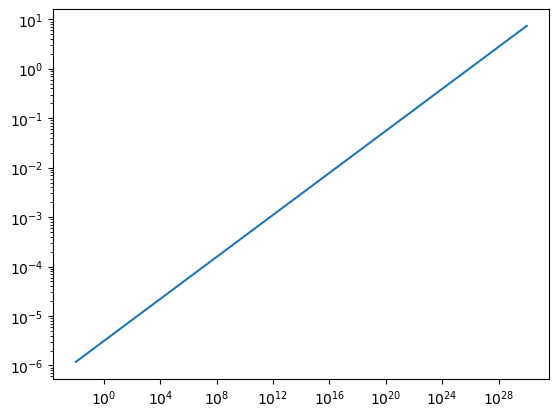

In [86]:
plt.loglog(L500s, T500s)

In [87]:
AGN_heating = np.array([test_nfw.total_heating_rate(rmin, rmax, rc, Linj=Linj_from_L500(logL)) for logL in np.log10(L500s)])

In [88]:
rad_cooling = np.array([test_nfw.total_cooling_rate(rmin,
                                             rmax, 
                                             Tb=(test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*T), 
                                             vol_rate='gfe').value for T in T500s])

In [89]:
dm_cooling= np.array([test_nfw.integrated_dm_cooling_rate(rmin, rmax, 1e-27, 1e-2, Tb=(test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*T)).value for T in T500s])

In [90]:
dm_cooling

array([6.41808719e+42, 9.73430784e+42, 1.49238434e+43, 2.31075711e+43,
       3.60914203e+43, 5.67864670e+43, 8.98867961e+43, 1.42963506e+44,
       2.28230518e+44, 3.65394893e+44, 5.86257843e+44, 9.42141841e+44,
       1.51587982e+45, 2.44116880e+45, 3.93381184e+45, 6.34215090e+45,
       1.02284796e+46, 1.65004657e+46, 2.66233050e+46, 4.29621965e+46,
       6.93351965e+46, 1.11905683e+47, 1.80623046e+47, 2.91548386e+47,
       4.70608846e+47, 7.59658198e+47, 1.22626037e+48, 1.97948290e+48,
       3.19539208e+48, 5.15820956e+48, 8.32675091e+48, 1.34416767e+49,
       2.16986268e+49, 3.50277090e+49, 5.65446742e+49, 9.12792446e+49,
       1.47350844e+50, 2.37866569e+50, 3.83985058e+50, 6.19862469e+50,
       1.00063671e+51, 1.61531629e+51, 2.60758667e+51, 4.20939771e+51,
       6.79518349e+51, 1.09693888e+52, 1.77077623e+52, 2.85854442e+52,
       4.61451659e+52, 7.44916309e+52])

In [91]:
dm_cooling_24= np.array([test_nfw.integrated_dm_cooling_rate(rmin, 
                                                             rmax, 
                                                             1e-24, 
                                                             1e-2, 
                                                             Tb=(test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*T)).value for T in T500s])

In [100]:
dm_cooling_25= np.array([test_nfw.integrated_dm_cooling_rate(rmin, 
                                                             rmax, 
                                                             1e-25, 
                                                             1e-2, 
                                                             Tb=(test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*T)).value for T in T500s])


In [101]:
dm_cooling_26= np.array([test_nfw.integrated_dm_cooling_rate(rmin, 
                                                             rmax, 
                                                             1e-26, 
                                                             1e-2, 
                                                             Tb=(test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*T)).value for T in T500s])

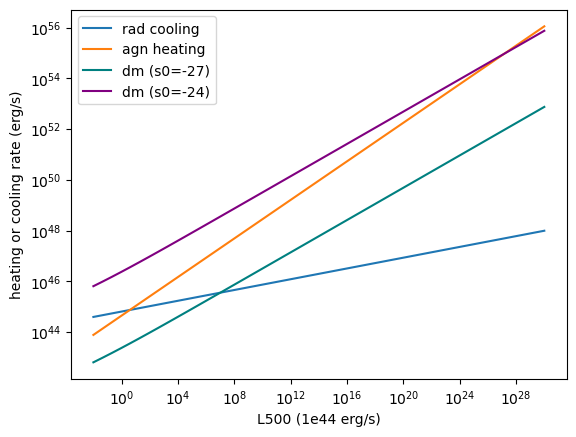

In [99]:
plt.loglog(L500s, rad_cooling, label='rad cooling')
plt.loglog(L500s, AGN_heating, label='agn heating')
plt.loglog(L500s, dm_cooling, label='dm (s0=-27)', color='teal')
plt.loglog(L500s, dm_cooling_24, label='dm (s0=-24)', color='purple')

plt.xlabel('L500 (1e44 erg/s)')
plt.ylabel('heating or cooling rate (erg/s)')

plt.legend()
#plt.xlim(1e-1, 1e2)
#plt.ylim(1e43, 1e47)

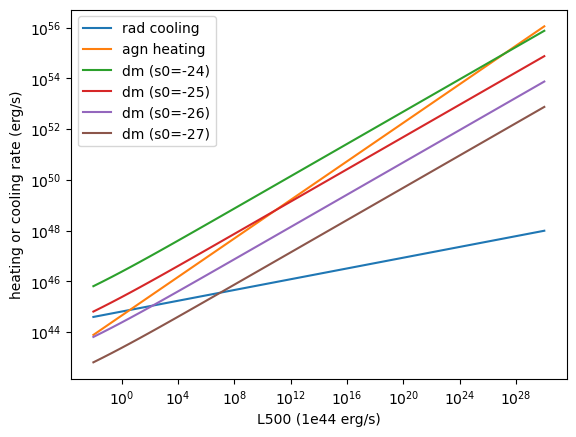

In [103]:
plt.loglog(L500s, rad_cooling, label='rad cooling')
plt.loglog(L500s, AGN_heating, label='agn heating')

plt.loglog(L500s, dm_cooling_24, label='dm (s0=-24)')
plt.loglog(L500s, dm_cooling_25, label='dm (s0=-25)')
plt.loglog(L500s, dm_cooling_26, label='dm (s0=-26)')
plt.loglog(L500s, dm_cooling, label='dm (s0=-27)')

plt.xlabel('L500 (1e44 erg/s)')
plt.ylabel('heating or cooling rate (erg/s)')

plt.legend()

In [118]:
p0s = [(i, -1) for i in range(-40, -22)]


In [119]:
obs = np.array([nfw.L500.value for nfw in nfws])
obs

array([0.846881, 1.086002, 1.236332, 2.827248, 0.49467 , 2.164603,
       1.404549, 1.253723, 2.734146, 1.460216, 0.491051, 0.181484,
       0.467516, 0.763259, 4.237381, 0.561478, 0.669697, 0.334315,
       1.027456, 3.815928, 0.593611, 3.817746, 0.820253, 0.537529,
       1.200899, 0.664945, 0.725639, 1.85299 , 0.65502 , 1.004022,
       2.523686, 0.48661 , 0.778067, 0.63117 , 2.296714, 3.985723,
       0.971284, 0.447219, 1.684553, 0.551689, 0.996636, 1.495635,
       1.160127, 4.230388, 0.496316, 0.910497, 0.644568, 5.629624,
       2.169167, 0.401983, 0.904947, 1.500662, 0.620608, 4.295575,
       1.893646, 0.75324 , 0.696381, 0.317309, 1.093054, 0.739347,
       3.566213, 3.386654, 3.746717, 1.667482, 2.127767, 1.345772,
       2.405416, 0.786086, 3.179797, 0.034601, 2.714065, 1.181329,
       1.57021 , 9.458634, 0.691313, 1.542954, 1.800189, 2.208812,
       4.532349, 0.244269, 1.018847, 0.742068, 1.085118, 0.916499,
       0.811447, 0.365145, 1.890749, 1.050267, 0.878997, 1.108

In [120]:
variances = np.array([nfw.L_err for nfw in nfws])
variances

array([0.13670661, 0.08642763, 0.12415974, 0.31397369, 0.04313728,
       0.30714761, 0.16384222, 0.09262341, 0.22813716, 0.08604661,
       0.03988705, 0.01343183, 0.04116458, 0.05526068, 0.41251589,
       0.06529352, 0.08461261, 0.14423532, 0.08368238, 0.13354662,
       0.05293967, 0.68521146, 0.16840712, 0.06420011, 0.08803048,
       0.05397613, 0.05095171, 0.05974175, 0.09247889, 0.08103832,
       0.27186057, 0.04420151, 0.12611217, 0.11223306, 0.72202926,
       0.37494298, 0.08215428, 0.02087464, 0.1348663 , 0.03238636,
       0.04511578, 0.12950357, 0.04108408, 0.32180458, 0.04215004,
       0.12270911, 0.11068043, 0.46274367, 0.25272894, 0.0478984 ,
       0.07068461, 0.17055621, 0.0859321 , 0.41719844, 0.18992984,
       0.10071447, 0.20381975, 0.04476836, 0.15218548, 0.14416114,
       0.36157224, 0.5491423 , 0.44586848, 0.10539025, 0.22880869,
       0.08117163, 0.31134809, 0.0902454 , 0.20395955, 0.00705677,
       0.55065278, 0.18655662, 0.19420882, 0.96934794, 0.06006

In [121]:
log_liks = [log_lik(p0, obs, nfws, variances=variances) for p0 in p0s]

In [122]:
log_liks

[-33.5065764913239,
 -33.50657649132552,
 -33.50657649134187,
 -33.50657649150538,
 -33.50657649314079,
 -33.50657650949418,
 -33.506576673028775,
 -33.5065783083743,
 -33.50659466183099,
 -33.506758196514106,
 -33.50839355497983,
 -33.52474829419504,
 -33.688402342498584,
 -35.327458056995944,
 -48.108869557950804,
 -55.49996467229235,
 -55.5,
 -inf]

Text(0, 0.5, 'log likelihood')

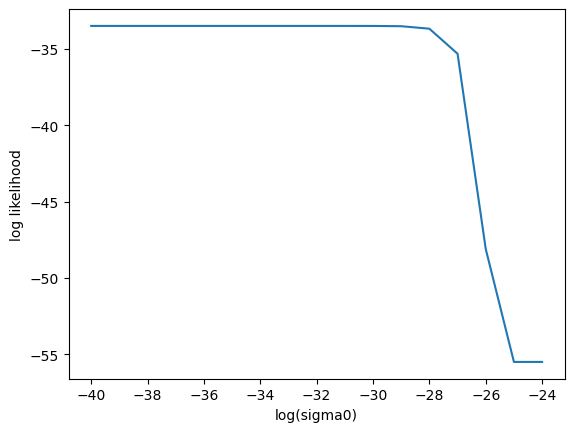

In [123]:
plt.plot(range(-40, -22), log_liks)
plt.xlabel('log(sigma0)')
plt.ylabel('log likelihood')